In [1]:
import torch
import os
import matplotlib.pyplot as plt
import random
from tqdm.auto import tqdm
import numpy as np
from torchvision import datasets, transforms
import torch.nn as nn
from torch.utils.data import Subset, Dataset
from datasets import load_dataset

from sklearn.metrics.pairwise import euclidean_distances
from scipy.spatial.distance import pdist
from scipy.stats import entropy

/home/nicole/miniconda3/envs/data-valuation-env/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import sys
sys.path.append("../src")
sys.path.append("..")
from src.utils import load_checkpoint

In [3]:
dir_data="../data/"
dir_tensors = os.path.join("../influences", "sst2")
dir_ckpt = "../checkpoint/"
dir_subset = os.path.join(dir_data,"subset_indices")
num_epochs = 100
ckpt_min = 1
ckpt_max = 100
p = 0.05
checkpoint_labels =  list([3, 6, 10, 13, 16, 20, 25, 40, 60, 80, 100])
epochs_range = range(1, num_epochs + 1)

In [4]:
class SST2EmbedDataset(Dataset):
    def __init__(self, embeddings, labels):
        self.embeddings = embeddings
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        embedding = torch.tensor(self.embeddings[idx])
        label = torch.tensor(self.labels[idx])
        return embedding, label

In [5]:
sst2_dataset = load_dataset("SetFit/sst2")
subset_indices = torch.load(f"{dir_subset}/sst2_embed_train_subset_indices.pt")
EMBEDDING_TRAIN_SST2 = "../data/sst-2/embedding_train.pt"
sst2_train_embeddings = torch.load(EMBEDDING_TRAIN_SST2)
sst2_embed_train_dataset = SST2EmbedDataset(sst2_train_embeddings, sst2_dataset['train']['label'])
sst2_embed_train_subset = Subset(sst2_embed_train_dataset, subset_indices)


Repo card metadata block was not found. Setting CardData to empty.


In [6]:
save_objs_dict = torch.load(f"{dir_tensors}/accuracies_and_losses.pt", weights_only=False)

train_losses = save_objs_dict["model_eval_obj"].train_losses
validation_losses = save_objs_dict["model_eval_obj"].validation_losses
accuracies = save_objs_dict["model_eval_obj"].accuracies

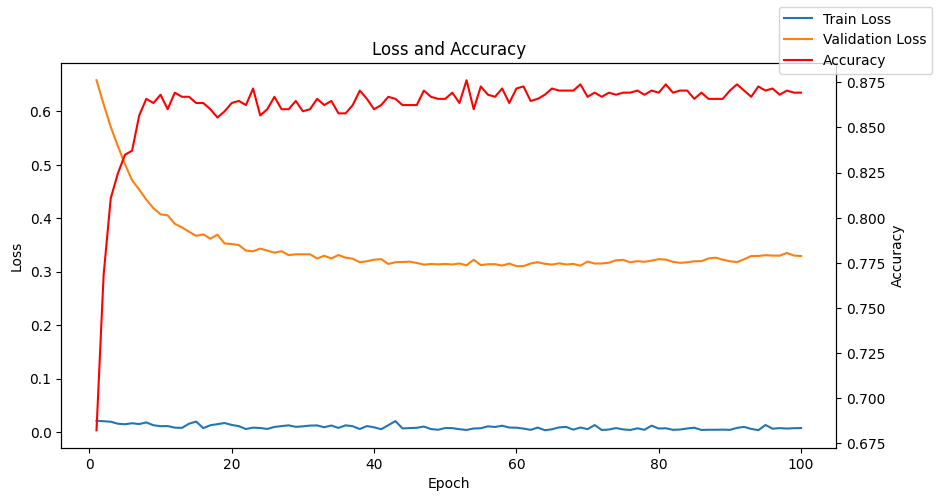

In [7]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.plot(epochs_range, validation_losses, label='Validation Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

plt.title('Loss and Accuracy')
fig.legend()
plt.show()

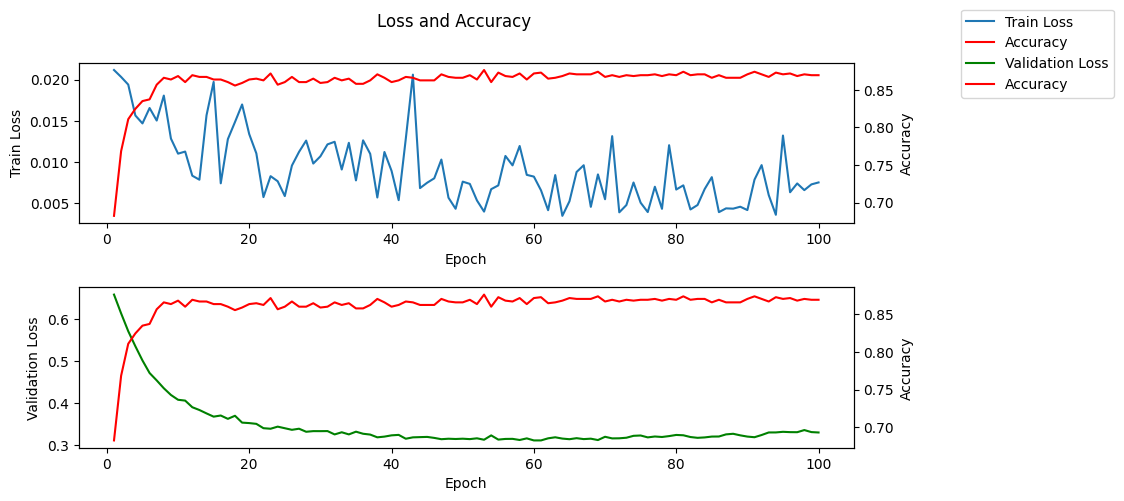

In [8]:
fig = plt.figure(figsize=(10, 5))
ax1 = fig.add_subplot(211)
ax1.plot(epochs_range, train_losses, label='Train Loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Train Loss')

ax2 = ax1.twinx()
ax2.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax2.set_ylabel('Accuracy')

ax3 = fig.add_subplot(212)
ax3.plot(epochs_range, validation_losses, label='Validation Loss', color='g')
ax4 = ax3.twinx()
ax3.set_xlabel('Epoch')
ax3.set_ylabel('Validation Loss')
ax4.plot(epochs_range, accuracies, label='Accuracy', color='r')
ax4.set_ylabel('Accuracy')

fig.suptitle('Loss and Accuracy')
fig.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.subplots_adjust(hspace=0.4)
plt.show()

# Influences

In [9]:
# Loading data
sst2_influences = save_objs_dict["sst2_influences"]
validate_list = save_objs_dict["validate_list"]
rand_list = save_objs_dict["rand_list"]


validate_dict = {
    "validate_accuracies": [],
    "validate_train_losses": [],
    "validate_validation_losses": []
}

rand_dict = {
    "rand_validate_accuracies": [],
    "rand_validate_train_losses": [],
    "rand_validate_validation_losses": []
}

for ckpt_idx, _ in enumerate(checkpoint_labels):
    validate_dict["validate_accuracies"].append(validate_list[ckpt_idx].accuracies)
    validate_dict["validate_train_losses"].append(validate_list[ckpt_idx].train_losses)
    validate_dict["validate_validation_losses"].append(validate_list[ckpt_idx].validation_losses)

    rand_dict["rand_validate_accuracies"].append(rand_list[ckpt_idx].accuracies)
    rand_dict["rand_validate_train_losses"].append(rand_list[ckpt_idx].train_losses)
    rand_dict["rand_validate_validation_losses"].append(rand_list[ckpt_idx].validation_losses)
x_vals =  list(range(1, num_epochs+1))
num_data = len(sst2_embed_train_subset)

In [10]:
checkpoints_filepaths = [os.path.join(dir_ckpt, "TextCNN", f"TextCNN_epoch_{epoch}_{epoch/num_epochs}.pth") for epoch in checkpoint_labels]

In [11]:

def top_last_influences(ckpt_influences, train_embeds, num_per_row=10, descending=True):
    top_inf_texts = []
    for influences in ckpt_influences:
        sorted_influences = torch.argsort(torch.from_numpy(influences), descending=descending)
        top_indexes = sorted_influences[:num_per_row]
        top_influential_train_data = [(train_embeds[index][0].detach().squeeze(0), train_embeds[index][1]) for index in top_indexes]
        top_inf_texts.append(top_influential_train_data)
    return top_inf_texts

def random_idx(checkpoint_influences, dataset, num_data, p):
    checkpoints_indices = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        indices = list(np.arange(len(dataset)))
        random_indices = random.sample(indices, num_select)
        checkpoints_indices.append(random_indices)
    return checkpoints_indices

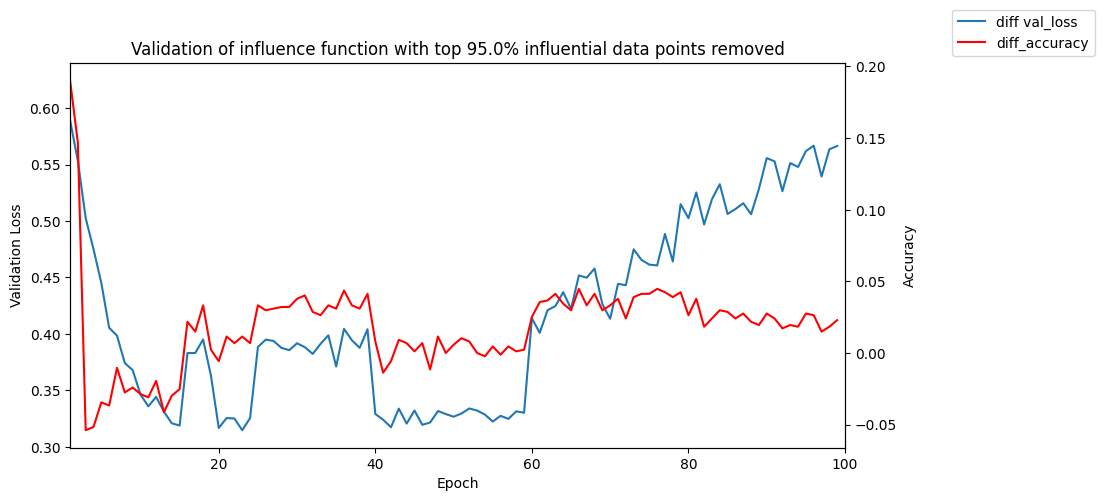

In [12]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
def concat_ckpt_metrics(metrics, ckpt_labels):
    integrate_metrics = []
    for i, metric in enumerate(metrics):
        prev_ckpt = ckpt_labels[i-1] if i > 0 else 0
        integrate_metrics.append(metric[prev_ckpt:])
    return np.concatenate(integrate_metrics)

diff_val_loss = concat_ckpt_metrics(validate_dict["validate_validation_losses"], checkpoint_labels) - concat_ckpt_metrics(rand_dict["rand_validate_train_losses"], checkpoint_labels) # suppose positive
diff_accuracy = concat_ckpt_metrics(rand_dict["rand_validate_accuracies"], checkpoint_labels) - concat_ckpt_metrics(validate_dict["validate_accuracies"], checkpoint_labels) # suppose positive

ax1.plot(diff_val_loss, label='diff val_loss')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Validation Loss')

ax2 = ax1.twinx()
ax2.plot(diff_accuracy, label='diff_accuracy', color='r')
ax2.set_ylabel('Accuracy')
plt.title(f'Validation of influence function with top {np.round(1-p, 2)*100}% influential data points removed')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

/tmp/ipykernel_165593/2715859468.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])
/tmp/ipykernel_165593/2715859468.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])
/tmp/ipykernel_165593/2715859468.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


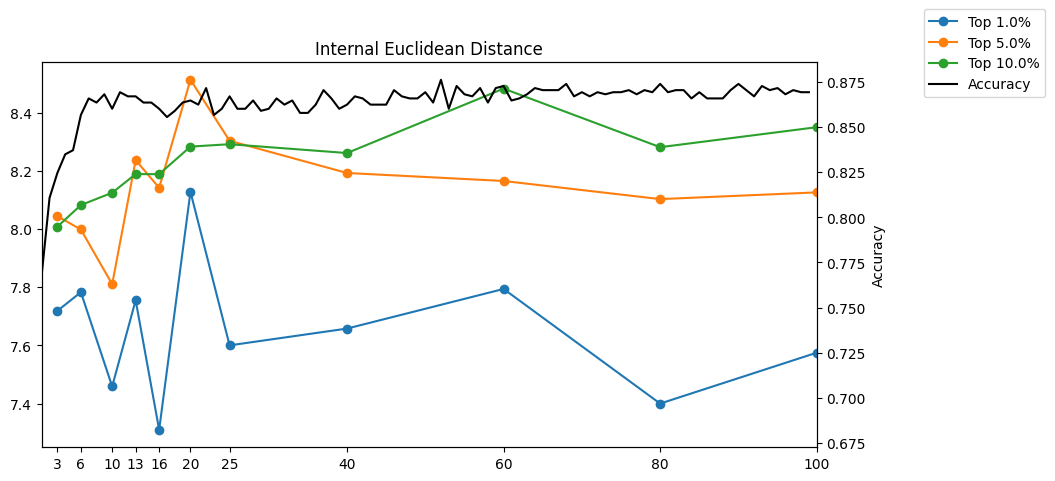

In [13]:
from sklearn.metrics.pairwise import euclidean_distances

# distance between text embeddings of within a single checkpoint
def calc_inter_dist(embeds):
    distances = euclidean_distances(embeds, embeds)
    mean_distance = np.mean(distances)
    return mean_distance


def calc_external_dist(inf_embeds, other_embeds):
    distances = euclidean_distances(inf_embeds, other_embeds)
    mean_distance = np.mean(distances)
    return mean_distance


fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
for p in [0.01, 0.05, 0.1]:
    int_distances = []
    top_inf_embeds = top_last_influences(sst2_influences, sst2_embed_train_subset, int(p*num_data))
    for ckpt, ckpt_embeds in enumerate(top_inf_embeds):
        embed_inputs = np.array([embed[0] for embed in ckpt_embeds])
        embed_inputs = embed_inputs[:, 0, :]
        mean_dist = calc_inter_dist(embed_inputs)
        int_distances.append(mean_dist)
    ax1.plot(checkpoint_labels, int_distances, 'o-', label=f"Top {p*100}%")
plt.title("Internal Euclidean Distance")
ax1.set_xticks(checkpoint_labels)

ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')
fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

In [14]:
from utils import random_p_data
EMBEDDING_TRAIN_SST2 = "../data/sst-2/embedding_train.pt"
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
sst2_embed_dataset_train = torch.load(EMBEDDING_TRAIN_SST2, map_location="cpu")

/tmp/ipykernel_165593/2715859468.py:10: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  embedding = torch.tensor(self.embeddings[idx])


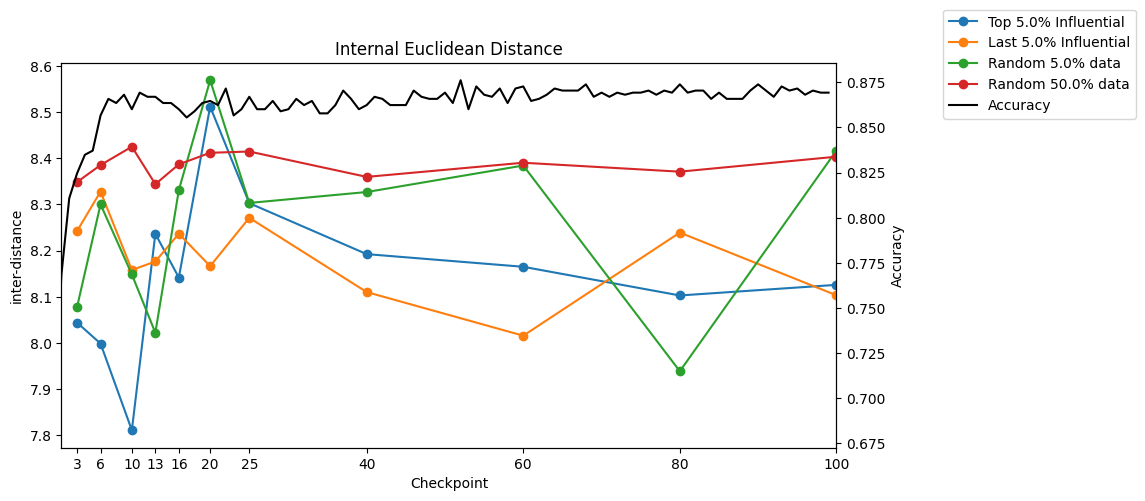

In [15]:
# from utils import random_p_data

p = 0.05
def random_p_data(checkpoint_influences, train_dataset, num_data, p=p):
    checkpoints_data = []
    for _ in checkpoint_influences:
        num_select = int(p * num_data)
        random_data = random.sample(list(train_dataset), num_select)
        random_data = [(data[0].detach().numpy().squeeze(0), data[1]) for data in random_data]
        checkpoints_data.append(random_data)
    return checkpoints_data
random_embeds = random_p_data(sst2_influences, sst2_embed_train_subset, num_data, p) #TODO: I changed from sst2_embed_dataset_train to sst2_embed_train_subset
random_embeds_large = random_p_data(sst2_influences, sst2_embed_train_subset, num_data, p*10)
last_ckpts_embeds = top_last_influences(sst2_influences, sst2_embed_train_subset, int(p*num_data), False) 
top_ckpts_embeds = top_last_influences(sst2_influences, sst2_embed_train_subset, int(num_data*p))

fig, ax1 = plt.subplots(figsize=(10, 5))
# ax2 = ax1.twinx()
ax1.set_xlim(min(x_vals), max(x_vals))
topinf_int_distances = []
for i in range(len(top_ckpts_embeds)):
    # each checkpoint
    embeds = np.array([embed[0] for embed in top_ckpts_embeds[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    topinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, topinf_int_distances, 'o-', label=f"Top {p*100}% Influential")

lastinf_int_distances = []
for i in range(len(last_ckpts_embeds)):
    # each checkpoint    
    embeds = np.array([embed[0] for embed in last_ckpts_embeds[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    lastinf_int_distances.append(repre)
ax1.plot(checkpoint_labels, lastinf_int_distances, 'o-', label=f"Last {p*100}% Influential")
    
rand_int_distances = []
for i in range(len(checkpoint_labels)):
    embeds = np.array([embed[0] for embed in random_embeds[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    rand_int_distances.append(repre)
ax1.plot(checkpoint_labels, rand_int_distances, 'o-', label=f"Random {p*100}% data")

rand_int_distances = []
for i in range(len(checkpoint_labels)):
    embeds = np.array([embed[0] for embed in random_embeds_large[i]])[:, 0, :]
    repre = calc_inter_dist(embeds)
    rand_int_distances.append(repre)
ax1.plot(checkpoint_labels, rand_int_distances, 'o-', label=f"Random {p*1000}% data")

ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("inter-distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.title("Internal Euclidean Distance")
plt.show()

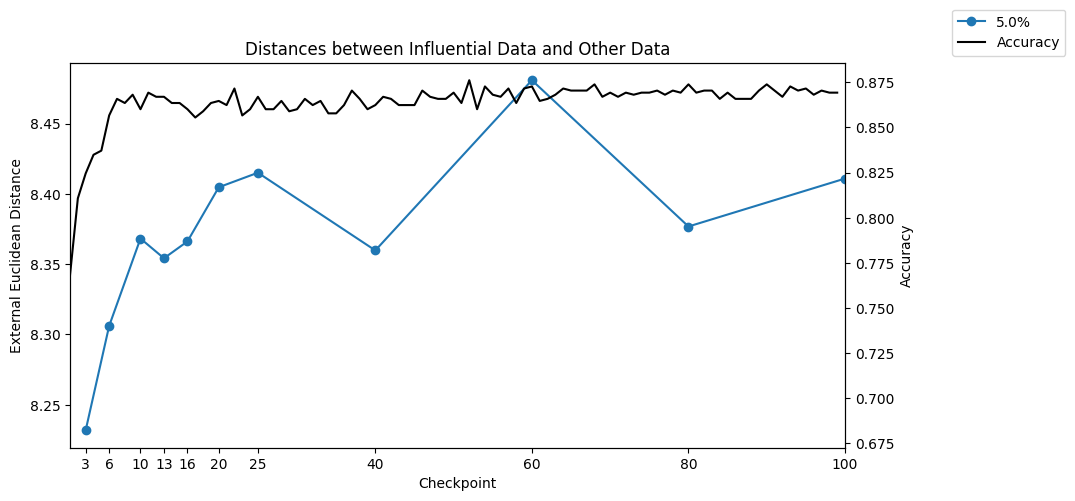

In [16]:
# Euclidean distance from influential points to other points
# random_embeds = random_p_data(sst2_influences, sst2_embed_dataset_train, num_data, p)

fig, ax1 = plt.subplots(figsize=(10, 5))
# ax2 = ax1.twinx()
plt.title("Distances between Influential Data and Other Data")
distances = []
for i, ckpt_embeds in enumerate(top_inf_embeds):
    inf_embeds =  np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    rand_embeds =  np.array([embed[0] for embed in random_embeds_large[i]])[:, 0, :]
    mean_dist = calc_external_dist(inf_embeds, rand_embeds)
    distances.append(mean_dist)
ax1.set_xlim(min(x_vals), max(x_vals))
ax1.plot(checkpoint_labels, distances, 'o-', label=f"{p * 100}%")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("External Euclidean Distance")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

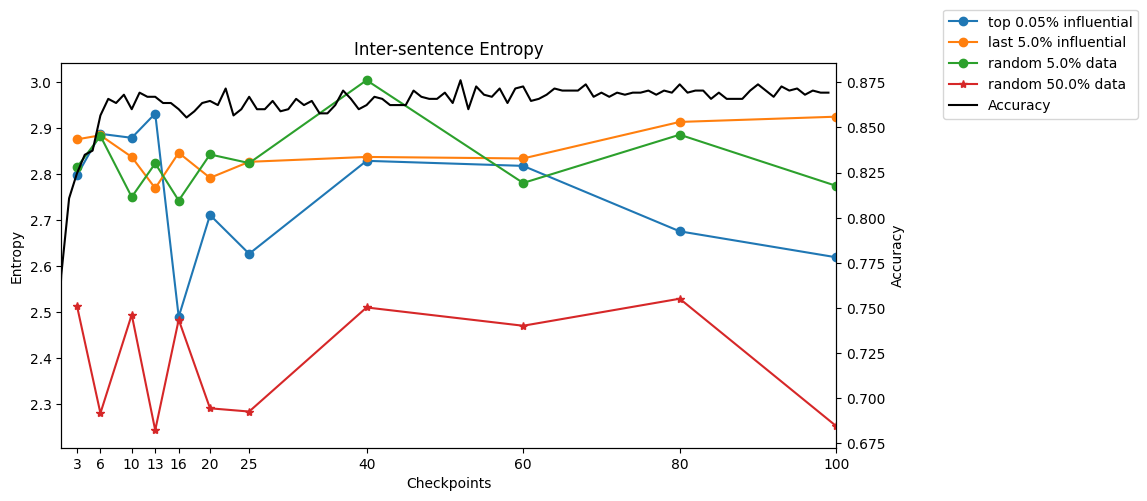

In [17]:
def inter_sentence_entropy(sentence_embeds):
    pairwise_distances = pdist(sentence_embeds, metric='cosine')
    distance_probs, _ = np.histogram(pairwise_distances, bins=30, density=True)
    distance_probs = distance_probs / np.sum(distance_probs)
    pairwise_entropy = entropy(distance_probs)
    return pairwise_entropy

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
# ax2 = ax1.twinx()
topinf_entropies = []
for ckpt, ckpt_embeds in enumerate(top_ckpts_embeds):
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    topinf_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, topinf_entropies, 'o-', label=f"top {p}% influential")

lastinf_pw_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    lastinf_pw_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, lastinf_pw_entropies, 'o-', label=f"last {p*100}% influential")

rand_pw_entropies = []
for ckpt_embeds in random_embeds:
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    rand_pw_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, rand_pw_entropies, 'o-', label=f"random {p*100}% data")

rand_pw_large_entropies = []
for ckpt_embeds in random_embeds_large:
    embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
    batch_entropy = inter_sentence_entropy(embeds)
    rand_pw_large_entropies.append(batch_entropy)
ax1.plot(checkpoint_labels, rand_pw_large_entropies, '*-', label=f"random {p*1000}% data")

plt.title("Inter-sentence Entropy")
ax1.set_xticks(checkpoint_labels)
ax1.set_xlabel("Checkpoints")
ax1.set_ylabel("Entropy")
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

/tmp/ipykernel_165593/501091311.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  probabilities = torch.nn.functional.softmax(torch.tensor(mean_embed), dim=0).numpy()


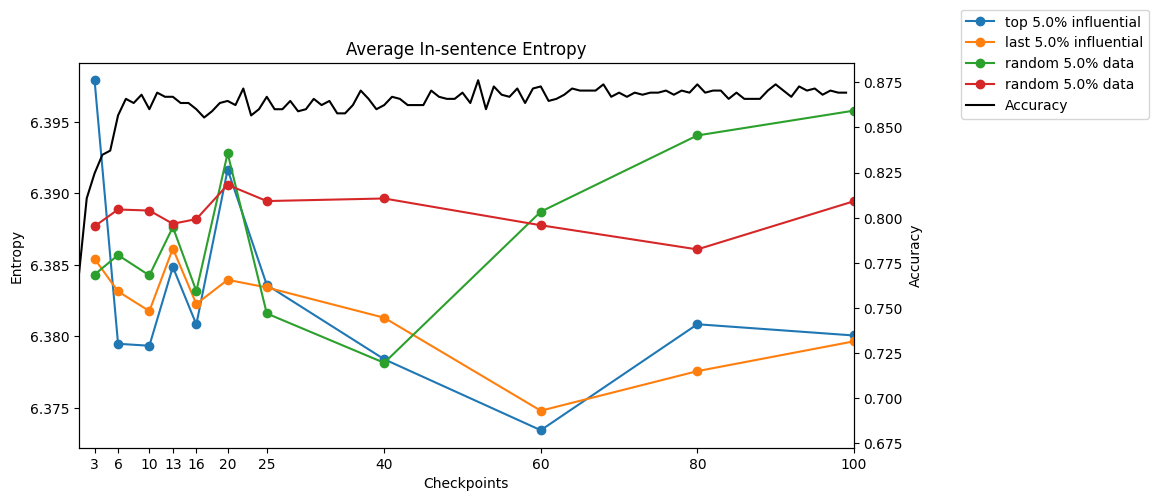

In [18]:
def inner_entropy(sentence_embed):
    mean_embed = sentence_embed[0, :]
    probabilities = torch.nn.functional.softmax(torch.tensor(mean_embed), dim=0).numpy()
    inner_entropy = entropy(probabilities)
    return inner_entropy

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))


topinf_entropies = []
for ckpt, ckpt_embeds in enumerate(top_ckpts_embeds):
    embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    topinf_entropies.append(np.mean(embed_entropies))
ax1.plot(checkpoint_labels, topinf_entropies, 'o-', label=f"top {p*100}% influential")

lastinf_entropies = []
for ckpt_embeds in last_ckpts_embeds:
    embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    lastinf_entropies.append(np.mean(embed_entropies))
ax1.plot(checkpoint_labels, lastinf_entropies, 'o-', label=f"last {p*100}% influential")

rand_entropies = []
for ckpt_embeds in random_embeds:
    rand_embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    rand_entropies.append(np.mean(rand_embed_entropies))

ax1.plot(checkpoint_labels, rand_entropies, 'o-', label=f"random {p*100}% data")

rand_entropies = []
for ckpt_embeds in random_embeds_large:
    rand_embed_entropies = [inner_entropy(embed[0]) for embed in ckpt_embeds]
    rand_entropies.append(np.mean(rand_embed_entropies))

ax1.plot(checkpoint_labels, rand_entropies, 'o-', label=f"random {p*100}% data")


plt.title("Average In-sentence Entropy")
ax1.set_xlabel("Checkpoints")
ax1.set_ylabel("Entropy")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()


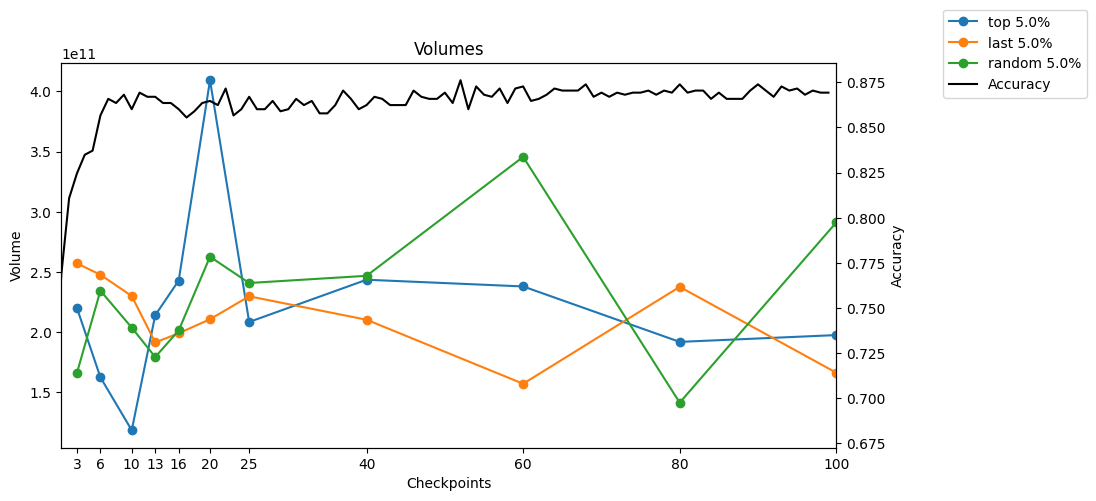

In [19]:
from sklearn.decomposition import PCA

def volume(sentences_embeds):
    return np.sqrt(np.linalg.det(sentences_embeds.T@sentences_embeds))

def pca(x, k):
    x_std = (x - np.mean(x, axis=0)) / (np.std(x, axis=0) + 1e-8)
    pca = PCA(n_components=k)
    pca.fit(x_std)
    return pca.components_

fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
label = ["top", "last", "random"]
for i, embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    volumes = []
    for ckpt_embeds in embeds:
        mean_embeds = np.array([embed[0] for embed in ckpt_embeds])[:, 0, :]
        W = pca(mean_embeds, 10)
        Z_embeds = mean_embeds @ W.T
        volumes.append(volume(Z_embeds))
    ax1.plot(checkpoint_labels, volumes, 'o-', label=f"{label[i]} {p*100}%")
    

plt.title("Volumes")
ax1.set_xlabel("Checkpoints")
ax1.set_ylabel("Volume")
ax1.set_xticks(checkpoint_labels)
ax2 = ax1.twinx()
ax2.set_ylabel("Accuracy")
ax2.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

# Retrain on Top n IP

In [20]:
from utils import pairwise_similarity, top_inf_indices

In [21]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("Device: ", device)

Device:  cuda


In [22]:
class TextCNN(nn.Module):
    def __init__(self, embed_dim=768, num_classes=2, kernel_sizes=[2, 3, 4], num_filters=2):
        super(TextCNN, self).__init__()
        self.convs = nn.ModuleList([
            nn.Conv2d(1, num_filters, (k, embed_dim)) for k in kernel_sizes
        ])
        self.dropout = nn.Dropout(0.5)
        self.fc = nn.Linear(len(kernel_sizes) * num_filters, num_classes)
        
    def forward(self, x):
        conv_outputs = []
        for conv in self.convs:
            conv_output = F.relu(conv(x)) # [batch size, num_filters, seq_len - kernel_size + 1, 1]
            conv_output_pool = F.max_pool2d(conv_output, (conv_output.shape[2], 1))
            conv_outputs.append(conv_output_pool.squeeze(3).squeeze(2))
        output = torch.cat(conv_outputs, dim=1)
        output = self.dropout(output)
        output = self.fc(output)
        return output

ValueError: only one element tensors can be converted to Python scalars

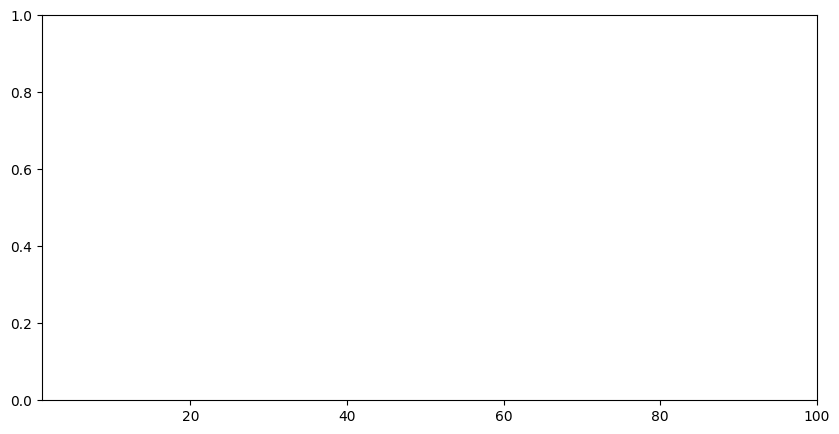

In [23]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))
labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    train_losses = [] # CrossEntropy loss
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        optimizer = torch.optim.Adam(TextCNN().parameters(), lr=0.0001)
        model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
        loss_fn = nn.CrossEntropyLoss()
        outputs = model(inputs)
        loss = loss_fn(outputs, expect_val)
        train_losses.append(loss.item())
    ax1.plot(checkpoint_labels, train_losses, 'o-', 
             label=f"{labels[j]} {p*100}% train loss")

plt.title("Train loss (BCE)")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Loss")
ax1.set_xticks(checkpoint_labels)
train_losses = torch.load("../influences/sst2/sst2_train_losses.pt")
ax1.plot(train_losses, label="train loss", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

ValueError: only one element tensors can be converted to Python scalars

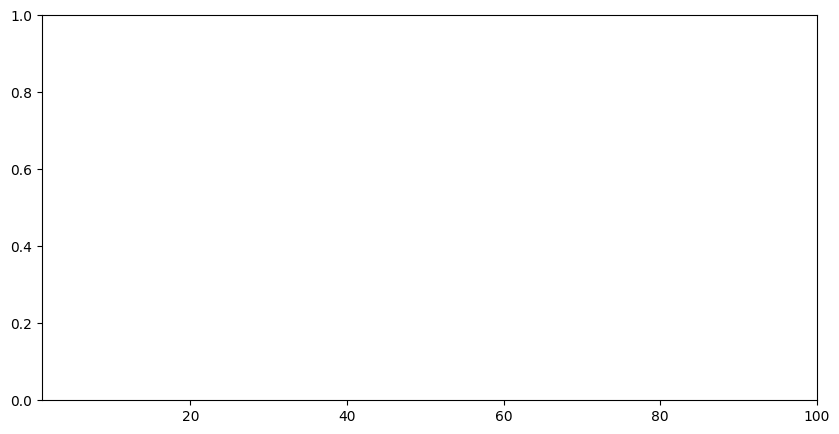

In [ ]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.set_xlim(min(x_vals), max(x_vals))

labels = ["top", "last", "random"]
for j, ckpts_embeds in enumerate([top_ckpts_embeds, last_ckpts_embeds, random_embeds]):
    accuracies = []
    
    for i, embeds in enumerate(ckpts_embeds):
        checkpoint = checkpoints_filepaths[i]
        inputs = torch.tensor([embed[0] for embed in embeds], dtype=torch.float32, device=device).unsqueeze(1)
        expect_val = torch.tensor([embed[1] for embed in embeds], device=device)
        model, optimizer, _, _ = load_checkpoint(TextCNN().to(device), optimizer, checkpoint)
        outputs = model(inputs)
        predictions = torch.argmax(outputs, dim=-1)
        accuracy = (predictions == expect_val).sum() / len(expect_val)
        accuracies.append(accuracy)
    ax1.plot(checkpoint_labels, accuracies, 'o-', 
             label=f"{labels[j]} {p*100}% accuracy")

plt.title("Training data accuracy")
ax1.set_xlabel("Checkpoint")
ax1.set_ylabel("Accuracy")
ax1.set_xticks(checkpoint_labels)
accuracies = torch.load("../influences/sst2/sst2_accuracies.pt")
ax1.plot(accuracies, label="Accuracy", color='k')

fig.legend(loc='upper left', bbox_to_anchor=(1,1))
plt.show()

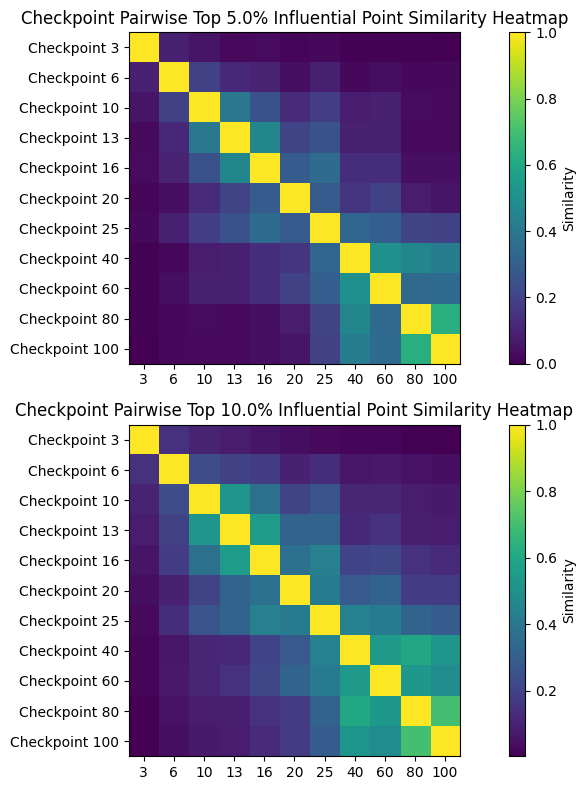

In [24]:
pw_similarities_lowp = pairwise_similarity(top_inf_indices(sst2_influences, int(p*num_data)))
pw_similarities_highp = pairwise_similarity(top_inf_indices(sst2_influences, int(0.1*num_data)))

fig = plt.figure(figsize=(10, 8))
ax1 = fig.add_subplot(211)
im1 = ax1.imshow(pw_similarities_lowp, cmap='viridis', interpolation='nearest')
fig.colorbar(im1, ax=ax1, label='Similarity')
ax1.set_xticks(range(len(checkpoint_labels)), checkpoint_labels)
ax1.set_yticks(range(len(checkpoint_labels)), [f'Checkpoint {i}' for i in checkpoint_labels])
ax1.set_title(f'Checkpoint Pairwise Top {p*100}% Influential Point Similarity Heatmap')

ax2 = fig.add_subplot(212)
im2 = ax2.imshow(pw_similarities_highp, cmap='viridis', interpolation='nearest')
fig.colorbar(im2, ax=ax2, label='Similarity')
ax2.set_xticks(range(len(checkpoint_labels)), checkpoint_labels)
ax2.set_yticks(range(len(checkpoint_labels)), [f'Checkpoint {i}' for i in checkpoint_labels])
ax2.set_title(f'Checkpoint Pairwise Top {0.1*100}% Influential Point Similarity Heatmap')
plt.tight_layout()

plt.show()